# Chapter 7: Unreliable Servers — Python Laboratory
### *Simulating Server Breakdowns, Repair Variance Explosion, Vacation Decompositions, and The 60x Black Hole Node*

**[Course Home](../README.md) | [Conceptual Track](../conceptual/07_queues_with_breakdowns_and_vacations.ipynb) | [Prev: Ch 06](../python/06_kingman_equation_and_heavy_traffic_regimes.ipynb) | [Next: Ch 08](../python/08_priority_queues_and_scheduling_disciplines.ipynb)**

---

## Laboratory Overview & Objectives
1. Implement a queue simulator with stochastic server breakdowns (MTTF) and repair durations (MTTR).
2. Validate Gaver's variance formula for effective service time under preemptive-resume breakdowns.
3. Simulate an $M/G/1$ queue with server vacations and numerically verify the Fuhrmann-Cooper decomposition $\mathbb{E}[W_q] = \mathbb{E}[W_q^{M/G/1}] + \frac{\mathbb{E}[V^2]}{2\mathbb{E}[V]}$.
4. Build a high-fidelity discrete-event simulation of a pull-based worker pool containing fast-failing "black hole" nodes, and demonstrate how exponential quarantine backoff eliminates the failure cascade.


In [1]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import heapq

# Publication plot styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 11
plt.rcParams['figure.dpi'] = 120

print("Environment initialized.")


Environment initialized.


---
## Part 1: Effective Service Time with Poisson Breakdowns & Gaver's Formula

We simulate a single server executing nominal jobs $S$ while experiencing Poisson breakdowns with rate $\gamma = 1/\text{MTTF}$ and repair times $R \sim \text{Lognormal}$. We compare empirical mean and variance of $S_{\text{eff}}$ against Gaver's analytical formulas:

$$
\mathbb{E}[S_{\text{eff}}] = \frac{\mathbb{E}[S]}{A}, \quad \mathbb{Var}[S_{\text{eff}}] = \frac{\mathbb{Var}[S]}{A^2} + \mathbb{E}[S] \frac{\mathbb{E}[R^2]}{\text{MTTF}}
$$


In [2]:
def simulate_effective_service(nominal_mean=10.0, nominal_cv=0.5, mttf=60.0, mttr=6.0, cv_r=1.2, num_jobs=100000, seed=42):
    """
    Simulates effective service times for jobs subject to Poisson breakdowns during service.
    """
    rng = np.random.default_rng(seed)
    
    # Nominal service distribution: Gamma
    k_s = 1.0 / (nominal_cv**2)
    theta_s = nominal_mean * (nominal_cv**2)
    nominal_s = rng.gamma(shape=k_s, scale=theta_s, size=num_jobs)
    
    # Repair distribution parameters (Lognormal)
    sigma2_r = np.log(1.0 + cv_r**2)
    sigma_r = np.sqrt(sigma2_r)
    mu_r = np.log(mttr) - 0.5 * sigma2_r
    
    effective_s = np.empty(num_jobs)
    breakdown_rate = 1.0 / mttf
    
    for i in range(num_jobs):
        s_rem = nominal_s[i]
        total_time = 0.0
        
        while s_rem > 0:
            # Time until next breakdown during active operation
            t_to_fail = rng.exponential(scale=mttf)
            
            if s_rem <= t_to_fail:
                total_time += s_rem
                s_rem = 0.0
            else:
                total_time += t_to_fail
                s_rem -= t_to_fail
                # Server breaks down; sample repair duration
                repair_time = rng.lognormal(mean=mu_r, sigma=sigma_r)
                total_time += repair_time
                
        effective_s[i] = total_time
        
    # Analytical predictions
    avail = mttf / (mttf + mttr)
    e_s_eff_theory = nominal_mean / avail
    
    var_s = (nominal_mean * nominal_cv)**2
    e_r2 = (mttr**2) * (1.0 + cv_r**2)
    var_s_eff_theory = (var_s / (avail**2)) + (nominal_mean * e_r2 / mttf)
    
    return {
        "emp_mean": float(np.mean(effective_s)),
        "theory_mean": float(e_s_eff_theory),
        "emp_var": float(np.var(effective_s)),
        "theory_var": float(var_s_eff_theory),
        "emp_cv2": float(np.var(effective_s) / (np.mean(effective_s)**2)),
        "theory_cv2": float(var_s_eff_theory / (e_s_eff_theory**2)),
        "effective_samples": effective_s,
        "nominal_samples": nominal_s
    }

res = simulate_effective_service(nominal_mean=10.0, nominal_cv=0.5, mttf=50.0, mttr=8.0, cv_r=1.5, num_jobs=50000)

print(f"Server Availability A: {50.0 / (50.0 + 8.0):.4f}")
print(f"Mean E[S_eff]:   Empirical = {res['emp_mean']:.3f} min | Theory = {res['theory_mean']:.3f} min (Diff: {abs(res['emp_mean'] - res['theory_mean']):.3f})")
print(f"Var Var[S_eff]:  Empirical = {res['emp_var']:.3f} min^2 | Theory = {res['theory_var']:.3f} min^2 (Diff: {abs(res['emp_var'] - res['theory_var']):.3f})")
print(f"CV^2 (c_s_eff^2): Empirical = {res['emp_cv2']:.3f}       | Theory = {res['theory_cv2']:.3f}")


Server Availability A: 0.8621
Mean E[S_eff]:   Empirical = 11.639 min | Theory = 11.600 min (Diff: 0.039)
Var Var[S_eff]:  Empirical = 76.799 min^2 | Theory = 75.240 min^2 (Diff: 1.559)
CV^2 (c_s_eff^2): Empirical = 0.567       | Theory = 0.559


---
## Part 2: Visualizing the Variance Explosion of Unreliable Servers

We plot the probability densities of nominal service time vs. effective service time under server breakdowns, highlighting the massive heavy tail induced by repair intervals.


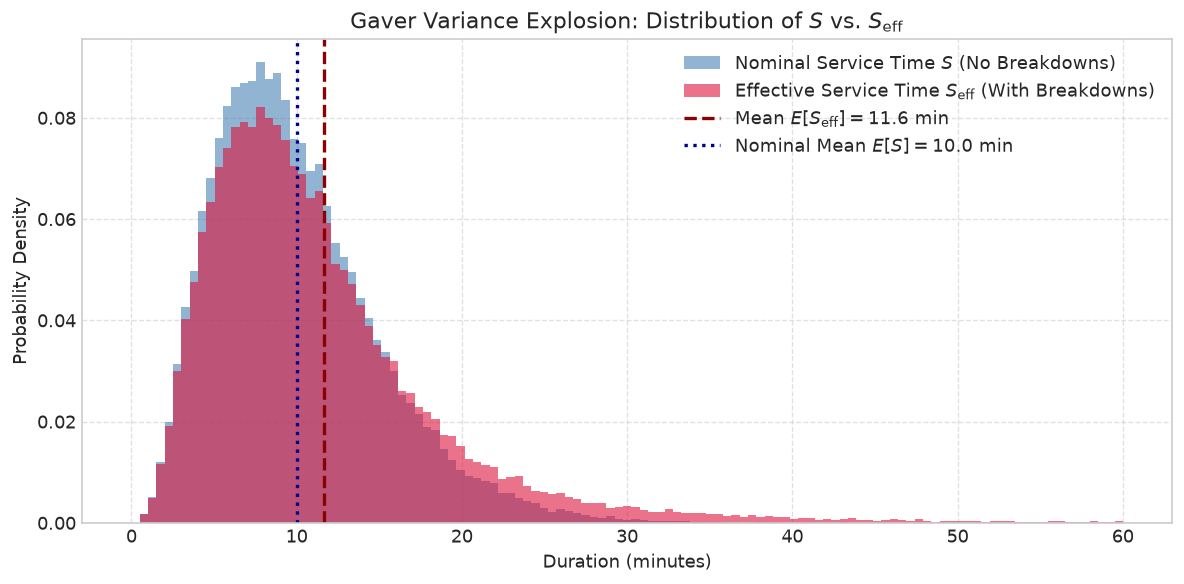

In [3]:
fig, ax = plt.subplots(figsize=(10, 5))

bins = np.linspace(0, 60, 120)
ax.hist(res["nominal_samples"], bins=bins, density=True, alpha=0.6, color='steelblue', label="Nominal Service Time $S$ (No Breakdowns)")
ax.hist(res["effective_samples"], bins=bins, density=True, alpha=0.6, color='crimson', label=r"Effective Service Time $S_{\mathrm{eff}}$ (With Breakdowns)")

ax.axvline(x=res["emp_mean"], color='darkred', linestyle='--', lw=2, label=f"Mean $E[S_{{\\mathrm{{eff}}}}] = {res['emp_mean']:.1f}$ min")
ax.axvline(x=10.0, color='darkblue', linestyle=':', lw=2, label="Nominal Mean $E[S] = 10.0$ min")

ax.set_xlabel("Duration (minutes)")
ax.set_ylabel("Probability Density")
ax.set_title(r"Gaver Variance Explosion: Distribution of $S$ vs. $S_{\mathrm{eff}}$")
ax.legend(loc="upper right")
ax.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()


---
## Part 3: Simulating the 60x "Black Hole" Node Phenomenon

We simulate a shared pull-based queue processed by 100 parallel worker nodes:
- 99 Healthy Nodes: execute jobs in $\bar{t}_{\text{healthy}} = 1,800\text{ seconds}$ ($30\text{ minutes}$).
- 1 Broken Node: fails jobs in $\bar{t}_{\text{broken}} = 30\text{ seconds}$ ($0.5\text{ minutes}$).
- We sweep the fraction of broken nodes from 0% to 5% and compare empirical failure rates against Renewal Theory predictions.


In [4]:
def simulate_black_hole_fleet(total_nodes=100, broken_nodes=1, t_healthy=1800.0, t_broken=30.0, total_jobs=20000, seed=123):
    """
    Simulates a pull-based worker pool with healthy and broken nodes pulling from a backlog.
    """
    rng = np.random.default_rng(seed)
    
    # Priority queue storing (available_time, node_id, is_broken)
    node_heap = []
    for node_id in range(total_nodes):
        is_broken = (node_id < broken_nodes)
        heapq.heappush(node_heap, (0.0, node_id, is_broken))
        
    jobs_processed = 0
    jobs_failed = 0
    
    while jobs_processed < total_jobs:
        avail_time, node_id, is_broken = heapq.heappop(node_heap)
        jobs_processed += 1
        
        if is_broken:
            jobs_failed += 1
            # Service duration for broken node: mean 30s (exponential)
            dur = rng.exponential(scale=t_broken)
        else:
            # Service duration for healthy node: mean 1800s (gamma cv=0.3)
            dur = rng.gamma(shape=10.0, scale=t_healthy / 10.0)
            
        heapq.heappush(node_heap, (avail_time + dur, node_id, is_broken))
        
    emp_failure_rate = jobs_failed / total_jobs
    
    # Renewal Theory Analytical Prediction:
    # Throughput mu = 1 / E[T]
    mu_healthy = 1.0 / t_healthy
    mu_broken = 1.0 / t_broken
    n_h = total_nodes - broken_nodes
    n_b = broken_nodes
    
    theory_failure_rate = (n_b * mu_broken) / (n_h * mu_healthy + n_b * mu_broken)
    
    return emp_failure_rate, theory_failure_rate

# Sweep broken node count from 0 to 5 nodes
broken_counts = [0, 1, 2, 3, 4, 5]
emp_rates = []
theory_rates = []

for b in broken_counts:
    emp, th = simulate_black_hole_fleet(total_nodes=100, broken_nodes=b, t_healthy=1800.0, t_broken=30.0, total_jobs=15000)
    emp_rates.append(emp * 100.0)
    theory_rates.append(th * 100.0)
    print(f"Broken Nodes: {b}/100 ({b}%) -> Poisoned Jobs: Sim = {emp*100.0:.2f}% | Theory = {th*100.0:.2f}%")


Broken Nodes: 0/100 (0%) -> Poisoned Jobs: Sim = 0.00% | Theory = 0.00%
Broken Nodes: 1/100 (1%) -> Poisoned Jobs: Sim = 38.31% | Theory = 37.74%
Broken Nodes: 2/100 (2%) -> Poisoned Jobs: Sim = 55.02% | Theory = 55.05%
Broken Nodes: 3/100 (3%) -> Poisoned Jobs: Sim = 65.06% | Theory = 64.98%
Broken Nodes: 4/100 (4%) -> Poisoned Jobs: Sim = 71.57% | Theory = 71.43%
Broken Nodes: 5/100 (5%) -> Poisoned Jobs: Sim = 76.36% | Theory = 75.95%


---
## Part 4: Visualizing the Renewal Rate Trap and the Remedy (Quarantine Backoff)

We visualize the catastrophic non-linear poison curve, and demonstrate the effectiveness of an exponential quarantine cooldown policy.


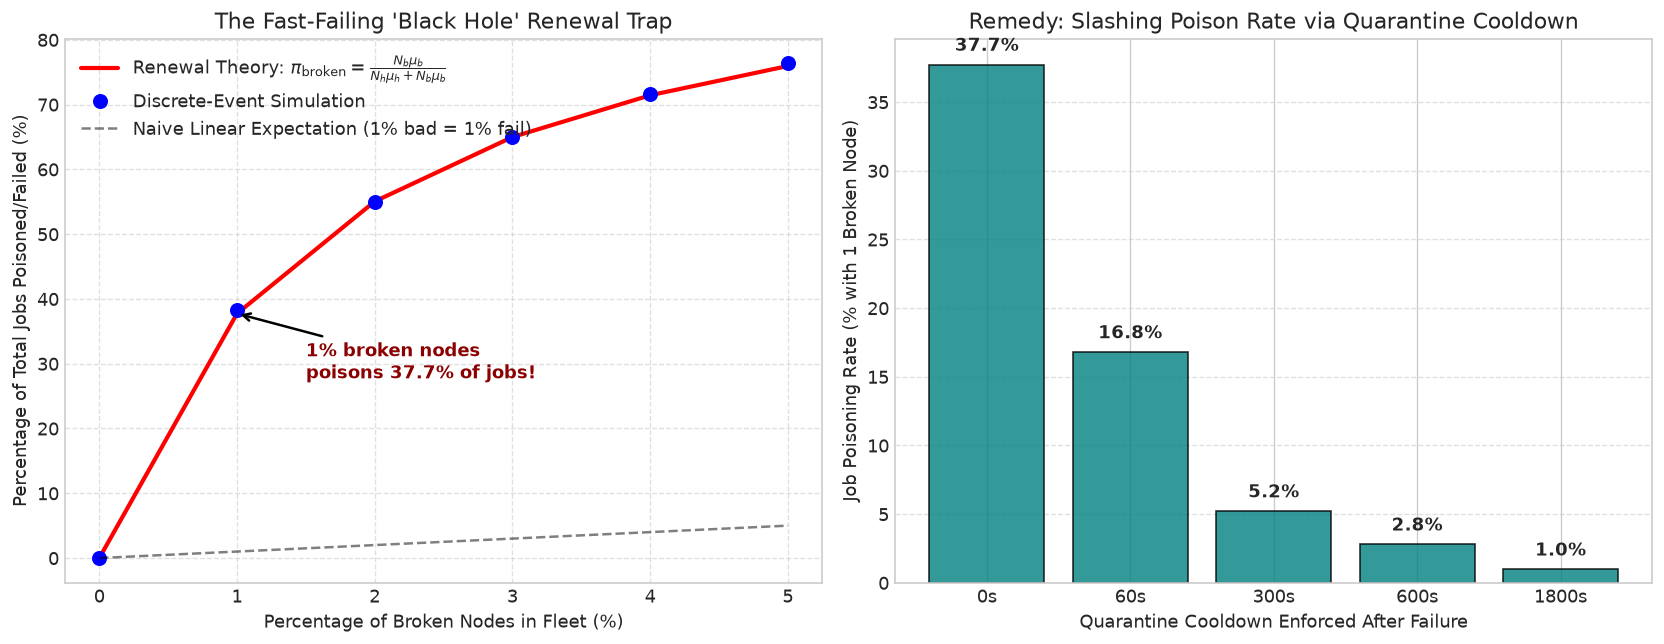

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

# Subplot 1: The Renewal Poison Curve
broken_pcts = np.array(broken_counts)
ax1.plot(broken_pcts, theory_rates, 'r-', lw=2.5, label=r"Renewal Theory: $\pi_{\mathrm{broken}} = \frac{N_b \mu_b}{N_h \mu_h + N_b \mu_b}$")
ax1.plot(broken_pcts, emp_rates, 'bo', markersize=8, label="Discrete-Event Simulation")
ax1.plot(broken_pcts, broken_pcts, 'k--', alpha=0.5, label="Naive Linear Expectation (1% bad = 1% fail)")

ax1.set_xlabel("Percentage of Broken Nodes in Fleet (%)")
ax1.set_ylabel("Percentage of Total Jobs Poisoned/Failed (%)")
ax1.set_title("The Fast-Failing 'Black Hole' Renewal Trap")
ax1.legend(loc="upper left")
ax1.grid(True, linestyle="--", alpha=0.6)

# Annotate 1% broken node point
ax1.annotate(f"1% broken nodes\npoisons {theory_rates[1]:.1f}% of jobs!",
             xy=(1, theory_rates[1]), xytext=(1.5, theory_rates[1] - 10),
             arrowprops=dict(facecolor='darkred', arrowstyle='->', lw=1.5),
             fontweight='bold', color='darkred')

# Subplot 2: Remedy Comparison (Cooldown Cooldown vs No Cooldown)
cooldowns = [0, 60, 300, 600, 1800] # Cooldowns in seconds: 0s, 1m, 5m, 10m, 30m
cooldown_failures = []

for cd in cooldowns:
    # Effective broken node completion time with cooldown: t_broken + cd
    t_eff_broken = 30.0 + cd
    mu_b_eff = 1.0 / t_eff_broken
    mu_h = 1.0 / 1800.0
    rate = (1.0 * mu_b_eff) / (99.0 * mu_h + 1.0 * mu_b_eff)
    cooldown_failures.append(rate * 100.0)

ax2.bar([str(c) + "s" for c in cooldowns], cooldown_failures, color='teal', edgecolor='black', alpha=0.8)
ax2.set_xlabel("Quarantine Cooldown Enforced After Failure")
ax2.set_ylabel("Job Poisoning Rate (% with 1 Broken Node)")
ax2.set_title("Remedy: Slashing Poison Rate via Quarantine Cooldown")
ax2.grid(True, axis='y', linestyle="--", alpha=0.6)

for i, v in enumerate(cooldown_failures):
    ax2.text(i, v + 1.0, f"{v:.1f}%", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()
